# Modeling Human Activity States with a Hidden Markov Model

**Formative 2 – Hidden Markov Models**

This notebook builds a complete pipeline that infers four hidden human-activity states
— **still, standing, walking, jumping** — from smartphone accelerometer and gyroscope
signals recorded with the *Sensor Logger* app.

Pipeline:

1. Load the labelled recordings and inspect raw signals
2. Pre-process: trim press-start / press-stop motion, harmonise the sampling rate
3. Window the signals (window size justified from the sampling rate)
4. Extract time-domain and frequency-domain (FFT) features per window
5. Normalise features (log + z-score, fitted on training data only)
6. Define the HMM: hidden states *Z*, observations *X*, transition matrix *A*,
   emission model *B*, initial distribution *π*
7. Implement **forward, backward, Baum–Welch (EM with a log-likelihood convergence check)
   and Viterbi** from scratch in NumPy
8. Train, visualise the learned transition / emission probabilities
9. Evaluate on **two unseen multi-activity test sessions**: decoded sequences,
   confusion matrix, sensitivity, specificity, accuracy

All figures and tables are written to `results/` so they can be dropped into the report.

In [22]:
import os, glob, math, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
try: 
     display
except NameError:
     display = print 

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
np. random.seed(42)

DATA_DIR = "data"
RESULTS_DIR = "results"
FIG_DIR = os.path.join(RESULTS_DIR, "figure")
os.makedirs(FIG_DIR, exist_ok=True)

# Hidden states, in a fixed order used everywhere below
STATES = ["still", "standing", "walking", "jumping"]
STATE_IDX = {s: i for i, s in enumerate(STATES)}
K = len(STATES)

# Pre process

TRIM_S = 1.0
FS_TARGET = 50.0
WIN_S = 2.0
HOP_S = 1.0

def savefig (name):
    path = os.path.join(FIG_DIR, name)
    plt.savefig(path, bbox_inches="tight")
    print(f"Saved figure to {path}")

## 1. Data loading and inspection

Every recording was exported from Sensor Logger (iPhone 13, iOS) and merged into one CSV with
a timestamp column (`time_s`), the three accelerometer axes (m/s², gravity removed), the three
gyroscope axes (rad/s) and the activity label. `data/manifest.csv` lists every file with its
source recording, device, sampling rate and duration.

* `data/train/` – 52 short clips (13 per activity, 6–11 s each) used for training
* `data/test/`  – 8 long recordings (40–86 s, recorded in separate later sessions) that are
  never used for training, plus two multi-activity **test sessions** built by chaining them

In [23]:
manifest = pd.read_csv(os.path.join(DATA_DIR, "manifest.csv"))
train_files = sorted(glob.glob(os.path.join(DATA_DIR, "train", "*.csv")))
print(f"Found {len(train_files)} training files")

summary = (manifest[manifest.split == "train"]
           .groupby("activity")
           .agg(n_files=("file", "count"), total_seconds=("duration_s", "sum"),
           sampling_rate=("sampling_rate_hz", "mean"))
          .reindex(STATES))
summary["total_minutes"] = summary["total_seconds"].round(1)
display(summary)

all_rec = manifest[~manifest.file.str.contains("session")]
print("\n all recordings (short + long) per activity:")
display(all_rec.groupby("activity").agg(n_files=("file", "count"), total_seconds=("duration_s", "sum")).reindex(STATES).round(1))

Found 52 training files


,n_files,total_seconds,sampling_rate,total_minutes
activity,,,,
still,13,103.79,99.5,103.8
standing,13,106.24,99.5,106.2
walking,13,112.62,99.5,112.6
jumping,13,104.17,99.5,104.2



 all recordings (short + long) per activity:


,n_files,total_seconds
activity,,
still,15,202.2
standing,15,193.8
walking,15,240.4
jumping,15,194.6


### Sampling rate per group member / device

The rubric asks for the sampling rate of each member's phone. All recordings in this dataset
come from one device, but the pre-processing step in Section 2 resamples **every** file onto
a common grid, so recordings from phones with other rates (e.g. 50 Hz Android devices or
100 Hz iPhones) would be harmonised in exactly the same way.

In [24]:
rates = (manifest[~manifest.file.str.contains("session")]
            .groupby(["activity", "platform"])
            .agg(recordings = ("file", "count"),
                 nominal_rate_hz = ("sampling_rate_hz", "mean"),
                 min_rate_hz = ("sampling_rate_hz", "min"),
                 max_rate_hz = ("sampling_rate_hz", "max"))
            .reset_index())
rates.insert(0, "member", ["member 1"] * len(rates))
display(rates)
rates.to_csv(os.path.join(RESULTS_DIR, "sampling_rates.csv"), index=False)

,member,activity,platform,recordings,nominal_rate_hz,min_rate_hz,max_rate_hz
0,member 1,jumping,ios,15,99.5,99.5,99.5
1,member 1,standing,ios,15,99.5,99.5,99.5
2,member 1,still,ios,15,99.5,99.5,99.5
3,member 1,walking,ios,15,99.5,99.5,99.5


### Raw signals, one clip per activity

Saved figure to results/figure/fig01_raw_signals.png


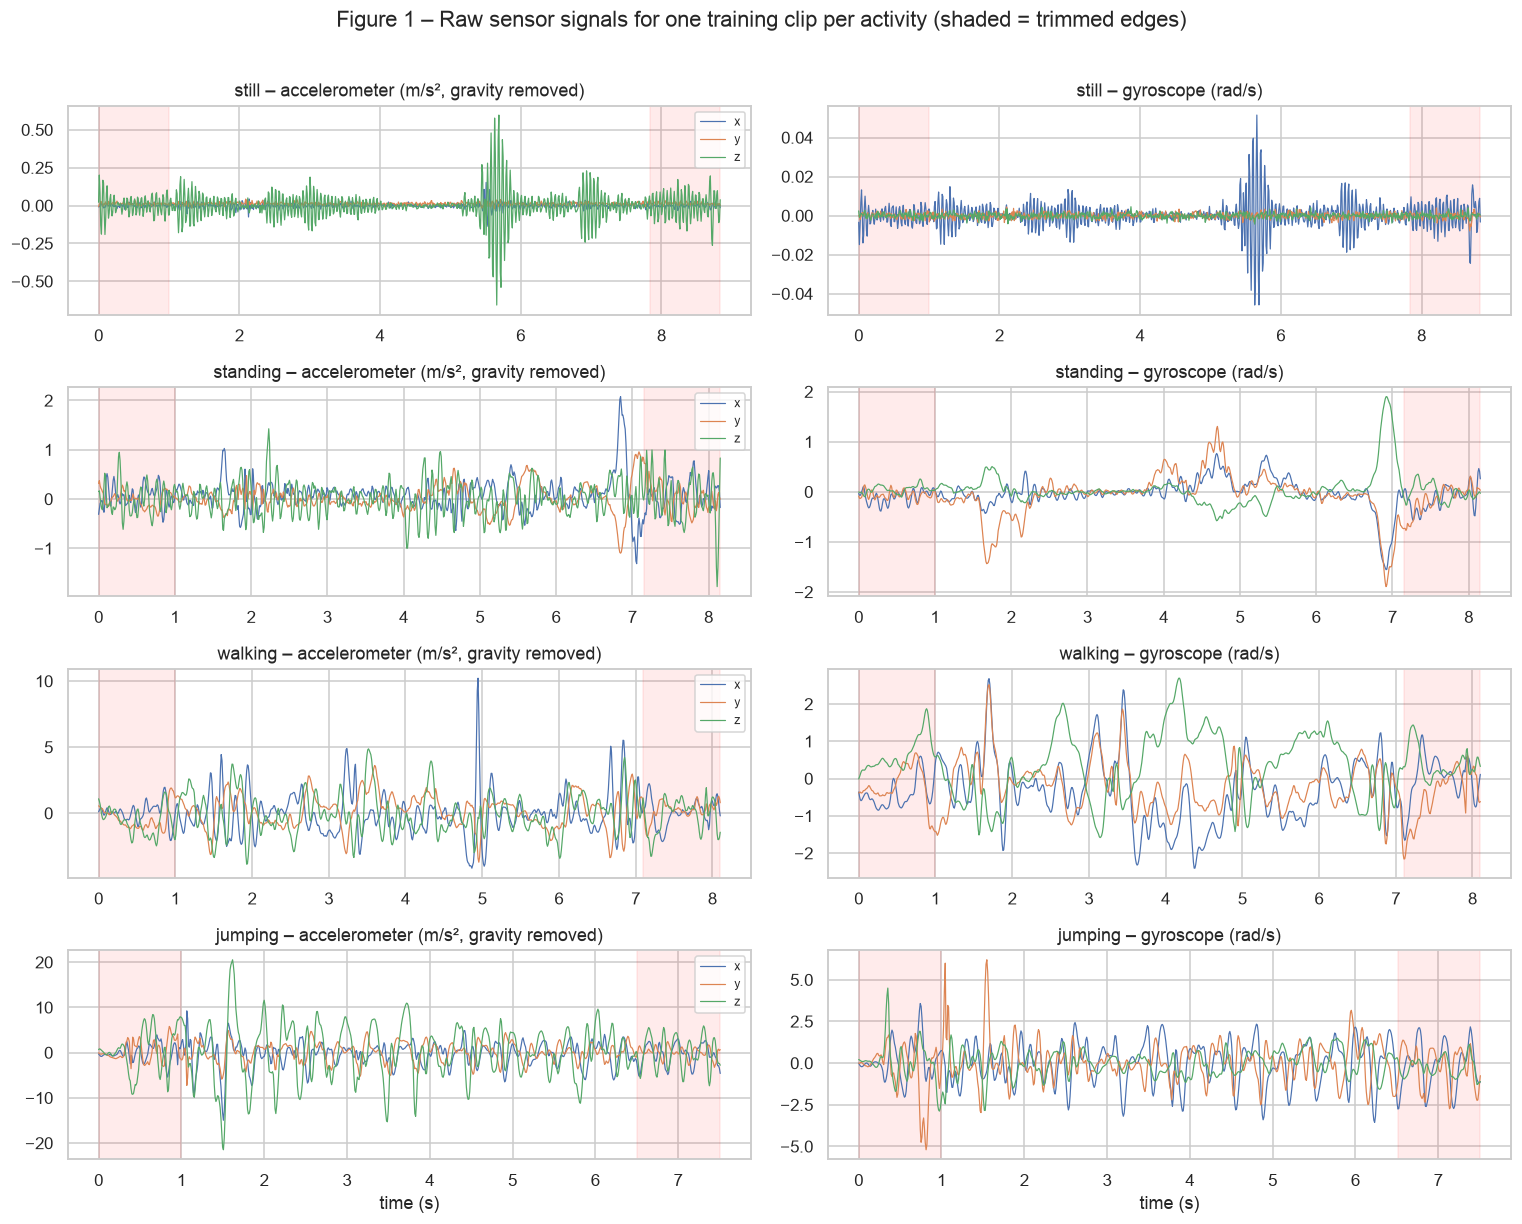

In [28]:
def load_csv(path):
    return pd.read_csv(path)

example_clips = {s: os.path.join(DATA_DIR, "train", f"{s}_02.csv") for s in STATES}

fig, axes = plt.subplots(K, 2, figsize=(14, 11))
for i, s in enumerate(STATES):
    df = load_csv(example_clips[s])
    for c in ["x", "y", "z"]:
        axes[i, 0].plot(df.time_s, df[f"acc_{c}"], lw=0.8, label=c)
        axes[i, 1].plot(df.time_s, df[f"gyr_{c}"], lw=0.8, label=c)

    axes[i, 0].set_title(f"{s} – accelerometer (m/s², gravity removed)")
    axes[i, 1].set_title(f"{s} – gyroscope (rad/s)")
    for ax in [axes[i, 0], axes[i, 1]]:
        ax.axvspan(0, TRIM_S, color="red", alpha=0.08)
        ax.axvspan(df.time_s.iloc[-1] - TRIM_S, df.time_s.iloc[-1], color="red", alpha=0.08)
    axes[i, 0].legend(loc="upper right", fontsize=8)
    axes[-1, 0].set_xlabel("time (s)"); 
    axes[-1, 1].set_xlabel("time (s)")

plt.suptitle("Figure 1 – Raw sensor signals for one training clip per activity (shaded = trimmed edges)", y=1.01)
plt.tight_layout()
savefig("fig01_raw_signals.png")
plt.show()

**Observations.** The four activities already look different in the raw signals:

* *still* – pure sensor noise, ≈ ±0.02 m/s² and ≈ ±0.005 rad/s
* *standing* – low-amplitude, irregular hand tremor and sway
* *walking* – a smooth, periodic pattern at roughly 2 Hz (one step per half-cycle)
* *jumping* – very large (±10 m/s²) periodic spikes from take-off and landing impacts

The shaded first and last second of each clip contain the motion of lowering the hand after
pressing *Start* and raising it to press *Stop*. Those parts are removed in the next step.

## 2. Pre-processing

### 2.1 Edge trimming
The first and last `TRIM_S = 1.0 s` of every short clip are discarded (the "press start" /
"press stop" motion visible in Figure 1).

### 2.2 Sampling-rate harmonisation
Sensor Logger timestamps every sample. The nominal rate of this phone is 100 Hz, but the
measured interval jitters slightly (median 10.05 ms → 99.5 Hz) and other phones in a group
would record at other rates. To make all recordings comparable we **linearly interpolate every
channel onto a uniform time grid at `FS_TARGET = 50 Hz`**. 50 Hz was chosen because

* human movement energy lives below ~20 Hz, so a 25 Hz Nyquist frequency loses nothing
* it is the lowest common rate of typical phones (many Android devices log at 50 Hz),
  so every device can be brought *down* to it without inventing data
* it halves the data volume relative to 100 Hz

Down-sampling from 100 Hz to 50 Hz is done after a light anti-alias step (2-sample moving
average) so that the high-frequency sensor noise above 25 Hz does not fold back into the band
of interest.

walking_02: raw 807 rows @ 99.5 Hz, 8.10 s  ->  pre-processed 305 rows @ 50 Hz, 6.08 s
Saved figure to results/figure/fig02_preprocessing.png


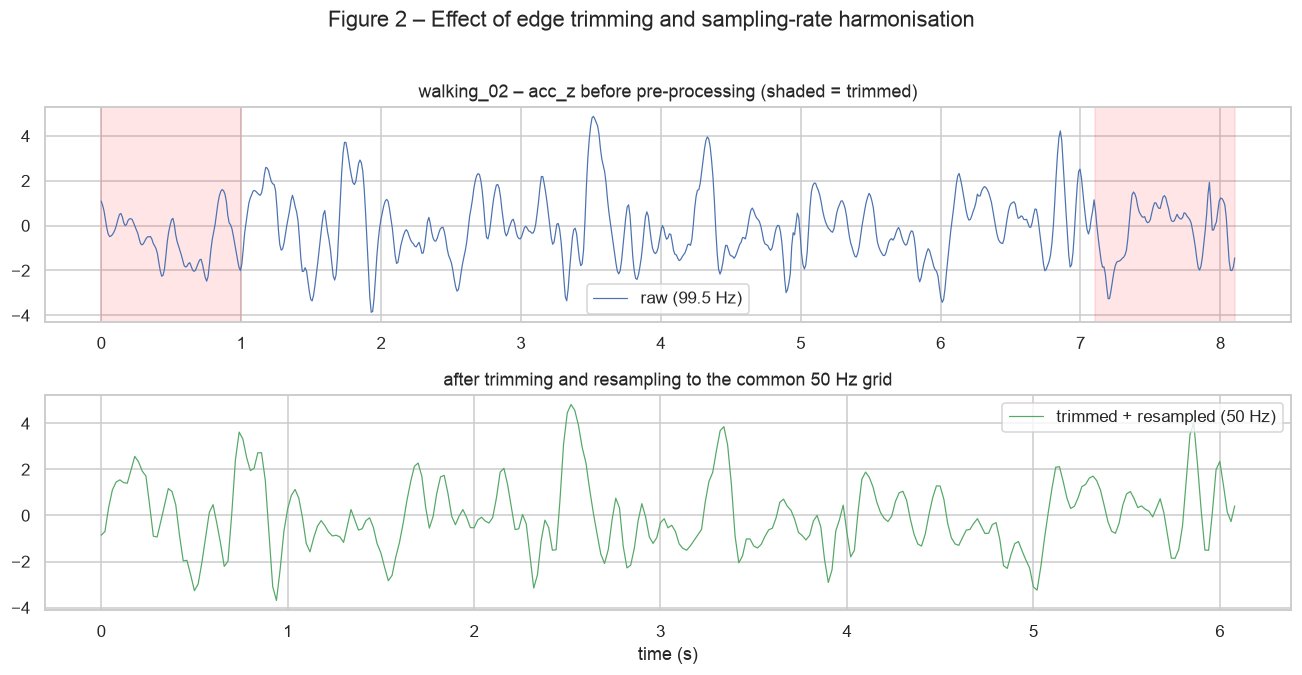

In [35]:
CHANNELS = ["acc_x", "acc_y", "acc_z", "gyr_x", "gyr_y", "gyr_z"]

def trim_edges(df, trim_s=TRIM_S):
    t_end = df.time_s.iloc[-1]
    out = df[(df.time_s >= trim_s) & (df.time_s <= t_end - trim_s)].copy()
    out["time_s"] = out["time_s"] - out["time_s"].iloc[0] 
    return out.reset_index(drop=True)

def resample_uniform(df, fs_target=FS_TARGET):
    t = df.time_s.values
    fs_in = 1.0/np.median(np.diff(t))
    grid = np.arange(t[0], t[-1], 1/fs_target)
    out = {"time_s": grid}
    for c in CHANNELS:
        x = df[c].values.astype(float)
        if fs_in>1.5*fs_target:
            x = np.convolve(x, np.ones(2)/2, mode="same")
        out[c] = np.interp(grid, t, x)
    out = pd.DataFrame(out)
    if "activity" in df.columns:
        idx = np.searchsorted(t, grid, side="left").clip(0, len(t)-1)
        out["activity"] = df["activity"].values[idx]
        return out, fs_in
def preprocess_clip(path, trim=True):
    df = load_csv(path)
    if trim:
        df = trim_edges(df)
    df, fs_in = resample_uniform(df)
    return df, fs_in

df_raw = load_csv(example_clips["walking"])
df_pp, fs_in = preprocess_clip(example_clips["walking"])
print(f"walking_02: raw {len(df_raw)} rows @ {fs_in:.1f} Hz, {df_raw.time_s.iloc[-1]:.2f} s  ->  "
      f"pre-processed {len(df_pp)} rows @ {FS_TARGET:.0f} Hz, {df_pp.time_s.iloc[-1]:.2f} s")

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=False)
ax[0].plot(df_raw.time_s, df_raw.acc_z, lw=0.8, label=f"raw ({fs_in:.1f} Hz)")
ax[0].axvspan(0, TRIM_S, color="red", alpha=0.1); ax[0].axvspan(df_raw.time_s.iloc[-1]-TRIM_S, df_raw.time_s.iloc[-1], color="red", alpha=0.1)
ax[0].set_title("walking_02 – acc_z before pre-processing (shaded = trimmed)"); ax[0].legend()
ax[1].plot(df_pp.time_s, df_pp.acc_z, lw=0.8, color="C2", label=f"trimmed + resampled ({FS_TARGET:.0f} Hz)")
ax[1].set_title("after trimming and resampling to the common 50 Hz grid"); ax[1].legend()
ax[1].set_xlabel("time (s)")
plt.suptitle("Figure 2 – Effect of edge trimming and sampling-rate harmonisation", y=1.02)
plt.tight_layout(); savefig("fig02_preprocessing.png"); plt.show()

## 3. Windowing

Features are computed over sliding windows. The window length is tied to the sampling rate:

| quantity | value | reason |
|---|---|---|
| sampling rate `FS_TARGET` | 50 Hz | common grid from Section 2 |
| window length `WIN_S` | 2.0 s = **100 samples** | long enough to contain ≥ 3 gait / jump cycles at the 1.5–2.5 Hz cadence seen in Figure 1, so periodic features are stable |
| FFT resolution | `FS_TARGET / N = 50 / 100 = 0.5 Hz` | the 0.5–5 Hz band where walking and jumping cadences live is resolved into ≥ 9 bins; a 1 s window would give only 1 Hz bins |
| hop `HOP_S` | 1.0 s = 50 samples (50 % overlap) | a new observation every second keeps the decoded sequence responsive at activity changes while doubling the number of training windows |

A 7 s trimmed clip therefore yields 6 windows; the long test recordings yield ~40–85 each.

In [38]:
N_WIN = int(WIN_S * FS_TARGET)
N_HOP = int(HOP_S * FS_TARGET)
print (f"window size = {N_WIN} samples, hop {N_HOP} samples, FFT bin width = {FS_TARGET/N_WIN:.2f} Hz")

def sliding_windows(df, n_win=N_WIN, n_hop=N_HOP):
    n = len(df)
    for start in range(0, n - n_win + 1, n_hop):
        w = df.iloc[start:start+n_win]
        label = w.activity.mode()[0] if "activity" in w.columns else None
        yield start, w, label

print ("windows in walking_02:", sum(1 for _ in sliding_windows(df_pp)))

window size = 100 samples, hop 50 samples, FFT bin width = 0.50 Hz
windows in walking_02: 5


## 4. Feature extraction

For every window we compute the accelerometer magnitude $|a| = \sqrt{a_x^2+a_y^2+a_z^2}$
and gyroscope magnitude $|\omega|$ (orientation-independent), then 10 features:

| # | feature | domain | why it separates the activities |
|---|---|---|---|
| 1 | `acc_mean` – mean of $|a|$ | time | overall movement intensity: still ≈ 0.03, standing ≈ 0.4, walking ≈ 2, jumping ≈ 5 m/s² |
| 2 | `acc_std` – std of $|a|$ | time | variability of intensity; jumping impacts give the largest spread |
| 3 | `acc_sma` – signal magnitude area $\frac1N\sum(|a_x|+|a_y|+|a_z|)$ | time | classic HAR energy measure, robust to single-axis spikes |
| 4 | `acc_range` – max − min of $|a|$ | time | peak-to-peak amplitude: captures landing impacts of jumping vs. smooth walking |
| 5 | `gyr_mean` – mean of $|\omega|$ | time | rotation intensity: separates *standing* (hand tremor, ≈ 0.3 rad/s) from *still* (≈ 0.003 rad/s) which look similar in acceleration |
| 6 | `gyr_std` – std of $|\omega|$ | time | rotation variability, high for walking (arm/hip rotation) |
| 7 | `acc_axis_corr` – mean absolute Pearson correlation between the three acc axes | time | periodic whole-body motion (walking, jumping) moves all axes together; noise (still) does not |
| 8 | `acc_dom_freq` – frequency of the largest FFT peak of $|a|$ in 0.5–12 Hz | frequency | cadence: walking ≈ 2 Hz, jumping ≈ 1.5–2.5 Hz, no stable peak for still/standing |
| 9 | `acc_spec_energy` – $\frac1N\sum_f |X(f)|^2$ (Parseval, DC removed) | frequency | total oscillatory power, orders of magnitude apart between activities |
| 10 | `acc_spec_entropy` – normalised entropy of the power spectrum | frequency | flat (noise-like) spectrum → entropy ≈ 1 for still/standing; one sharp peak → low entropy for walking/jumping |

Frequency features come from `np.fft.rfft` of the mean-removed, Hann-windowed magnitude signal.

In [44]:
TIME_FEATURES = ["acc_mean", "acc_std", "acc_sma", "acc_range", "gyr_mean", "gyr_std", "acc_axis_corr"]
FREQ_FEATURES = ["acc_dom_freq", "acc_spec_energy", "acc_spec_entropy"]
FEATURES = TIME_FEATURES + FREQ_FEATURES
# strictly-positive magnitude features that get a log transform before z-scoring (Section 5)
LOG_FEATURES = ["acc_mean", "acc_std", "acc_sma", "acc_range", "gyr_mean", "gyr_std", "acc_spec_energy"]

def power_spectrum(x, fs=FS_TARGET):
    
    x = x - x.mean()
    w = np.hanning(len(x))
    X = np.fft.rfft(x * w)
    freqs = np.fft.rfftfreq(len(x), d = 1.0 /fs)
    power = (np.abs(X)**2) / len(x)
    return freqs, power

def windowe_features(w):
    acc = w[["acc_x", "acc_y", "acc_z"]].values
    gyr = w[["gyr_x", "gyr_y", "gyr_z"]].values
    acc_mag = np.linalg.norm(acc, axis=1)
    a = np.linalg.norm(acc, axis=1)
    g = np.linalg.norm(gyr, axis=1)

    f = {
        "acc_mean": a.mean(),
        "acc_std": a.std(),
        "acc_sma": np.abs(acc).sum(axis=1).mean(),
        "acc_range": a.max() - a.min(),
        "gyr_mean": g.mean(),
        "gyr_std": g.std(),
    }

    c = np.corrcoef(acc.T)
    f["acc_axis_corr"] = np.nanmean(np.abs(c[np.triu_indices(3, k=1)]))
    freqs, power = power_spectrum(a)
    band = (freqs >= 0.5) & (freqs <= 12.0)
    f["acc_dom_freq"] = freqs[band][np.argmax(power[band])]
    f["acc_spec_energy"] = power[1:].sum()  # exclude DC component
    f["acc_spec_entropy"] = -(power * np.log(power + 1e-12)).sum() / np.log(len(power))
    return f

def extract_clip(df):
    row = []
    for start, w, label in sliding_windows(df):
        r = windowe_features(w)
        r["t_start"] = df.time_s.iloc[start]
        r["activity"] = label
        row.append(r)
    return pd.DataFrame(row)

train_clips = {}

for path in train_files:
    name = os.path.splitext(os.path.basename(path))[0]
    df, _ = preprocess_clip(path, trim=True)
    feats = extract_clip(df)
    feats.insert(0, "clip", name)
    train_clips[name] = feats

train_feat = pd.concat(train_clips.values(), ignore_index=True)
print(train_feat.shape[0], "training windows")
display(train_feat.groupby("activity")[FEATURES].median().reindex(STATES).round(3))
train_feat.to_csv(os.path.join(RESULTS_DIR, "train_features.csv"), index=False)

246 training windows


,acc_mean,acc_std,acc_sma,acc_range,gyr_mean,gyr_std,acc_axis_corr,acc_dom_freq,acc_spec_energy,acc_spec_entropy
activity,,,,,,,,,,
still,0.016,0.009,0.024,0.047,0.001,0.001,0.143,2.5,0.001,0.003
standing,0.315,0.187,0.458,0.932,0.180,0.147,0.292,0.5,0.674,0.596
walking,1.918,1.038,2.864,4.834,1.115,0.544,0.278,1.0,19.442,-1.210
jumping,4.956,2.244,6.985,10.371,1.353,0.714,0.256,6.0,94.629,-34.077


### Feature distributions per activity

Saved figure to results/figure/fig04_feature_distributions.png


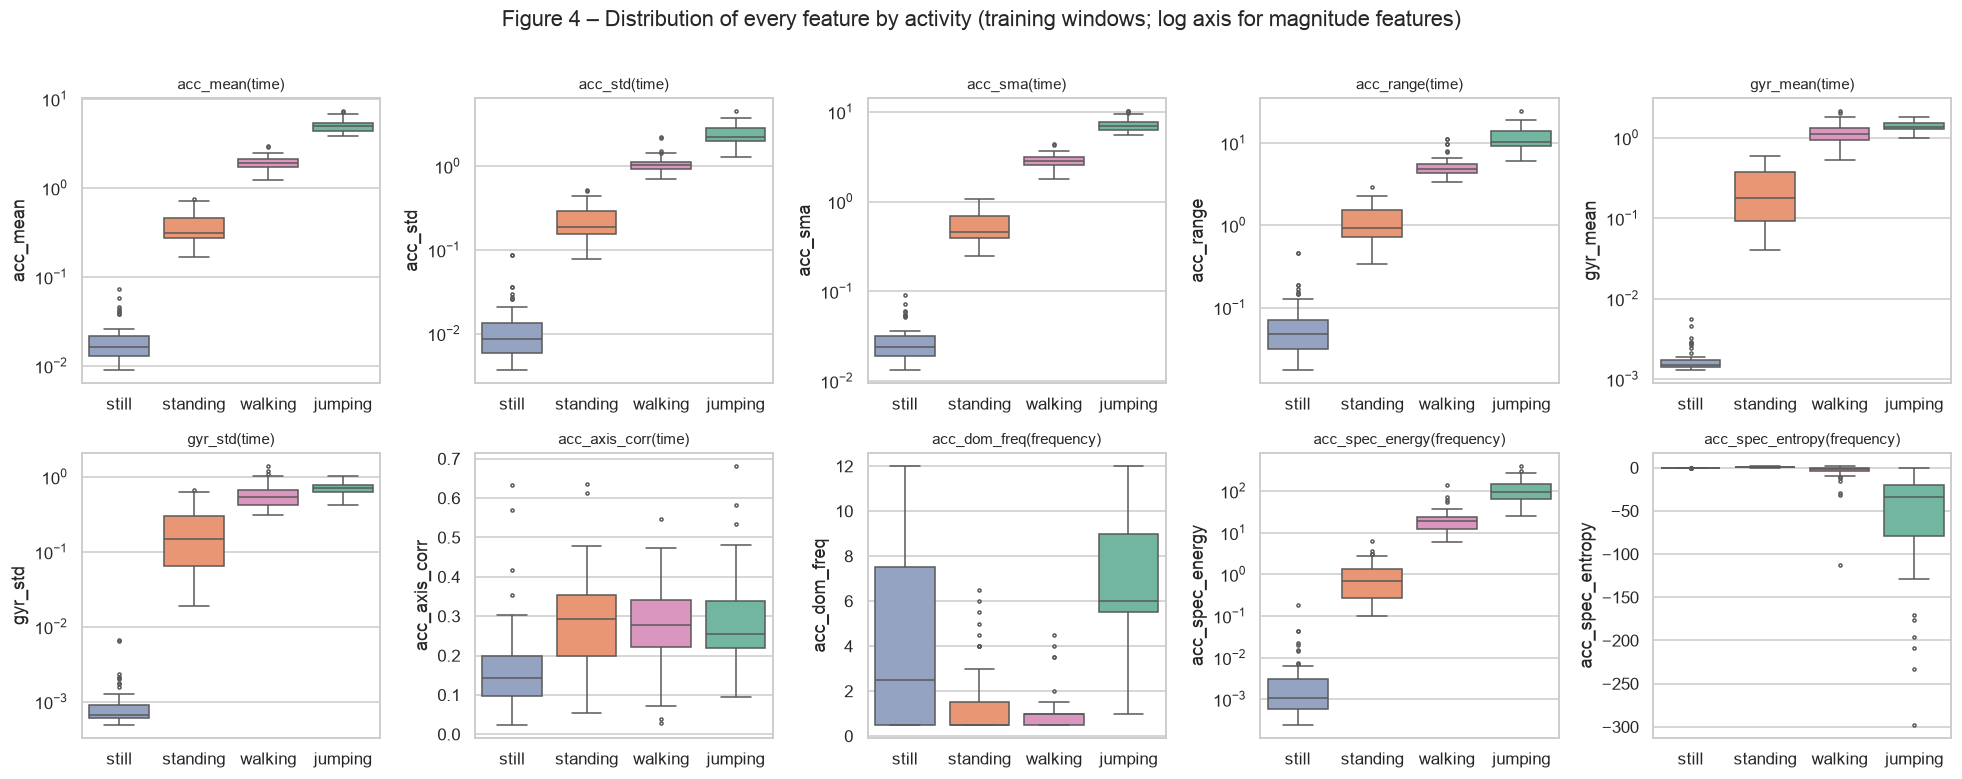

In [45]:
plot_df = train_feat.copy()
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, feat in zip(axes.ravel(), FEATURES):
    sns.boxplot(data=plot_df, x="activity", y=feat, order=STATES, ax=ax, hue="activity", palette="Set2", legend=False, fliersize=2)
    if feat in LOG_FEATURES:
        ax.set_yscale("log")
    ax.set_title(feat + ("(time)" if feat in TIME_FEATURES else "(frequency)"), fontsize=10)
    ax.set_xlabel("")
plt.suptitle("Figure 4 – Distribution of every feature by activity (training windows; log axis for magnitude features)", y=1.01)
plt.tight_layout(); savefig("fig04_feature_distributions.png"); plt.show()   

## 5. Normalisation

The HMM below uses Gaussian emission densities, which assume a roughly symmetric spread of each
feature within a state. Seven of the features are strictly positive *magnitude* quantities that
span **2–3 orders of magnitude** across activities (e.g. `acc_mean` ≈ 0.03 for still vs ≈ 5 for
jumping, Figure 4). Two steps make them well-behaved:

1. **log transform** (`log(x + 1e-4)`) of the magnitude features — turns multiplicative spread
   into additive spread and keeps the tiny *still* values from collapsing onto *standing*;
2. **z-score** every feature with the **training-set** mean and standard deviation
   ($z = (x-\mu_{train})/\sigma_{train}$), so all 10 features live on the same scale and no
   single large-valued feature (spectral energy, ~10²) dominates the Gaussian log-likelihood.

The same `μ_train`, `σ_train` are re-used for the test data — the test set never influences
the normalisation.

In [51]:
print ("log-transformed features:", LOG_FEATURES)

class FeatureScaler:
    def fit(self, df):
        X = self._log(df[FEATURES])
        self.mu = X.mean(axis=0).values
        self.sigma = X.std(axis=0).values + 1e-9
        return self
    def _log(self,X):
        X = X.copy()
        for c in LOG_FEATURES:
            X[c] = np.log(X[c] + 1e-12)
        return X
    def transform(self, df):
        return ((self._log(df[FEATURES]) - self.mu) / self.sigma).values
    
scaler = FeatureScaler().fit(train_feat)
norm_stats = pd.DataFrame({"feature": FEATURES, "log_transformed": [f in LOG_FEATURES for f in FEATURES], "train_mean": scaler.mu.round(3), "train_std": scaler.sigma.round(3)})

display(norm_stats)
norm_stats.to_csv(os.path.join(RESULTS_DIR, "normalisation_stats.csv"), index=False)

log-transformed features: ['acc_mean', 'acc_std', 'acc_sma', 'acc_range', 'gyr_mean', 'gyr_std', 'acc_spec_energy']


,feature,log_transformed,train_mean,train_std
0,acc_mean,True,-0.638,2.107
1,acc_std,True,-1.261,2.096
2,acc_sma,True,-0.263,2.108
3,acc_range,True,0.346,2.058
4,gyr_mean,True,-1.802,2.679
5,gyr_std,True,-2.389,2.713
6,acc_axis_corr,False,0.258,0.120
7,acc_dom_freq,False,3.157,3.328
8,acc_spec_energy,True,0.294,4.219
9,acc_spec_entropy,False,-15.298,40.214


## 6. HMM definition

| element | definition in this project |
|---|---|
| **Hidden states Z** | $Z_t \in$ {still, standing, walking, jumping}, $K=4$ |
| **Observations X** | $X_t \in \mathbb{R}^{10}$ – the normalised feature vector of window $t$ |
| **Transition matrix A** | $A_{ij} = P(Z_{t+1}=j \mid Z_t=i)$, a 4×4 row-stochastic matrix |
| **Emission model B** | $P(X_t \mid Z_t=k) = \mathcal{N}(X_t;\ \mu_k, \mathrm{diag}(\sigma_k^2))$ – one diagonal Gaussian per state (continuous observations, so B is a set of 4 mean vectors and 4 variance vectors rather than a discrete table) |
| **Initial probabilities π** | $\pi_k = P(Z_1 = k)$ |

### Which algorithms, and why

* **Forward–backward** computes $P(X_{1:T})$ (the likelihood used as the training objective) and
  the posteriors $\gamma_t(k)=P(Z_t=k\mid X_{1:T})$ in $O(TK^2)$. All of it is done in **log space**
  with log-sum-exp, otherwise products of hundreds of small densities underflow.
* **Baum–Welch (EM)** learns $A, B, \pi$ by maximising the likelihood. It is the right fit because
  the training clips give us feature sequences but the model parameters are unknown; EM is
  guaranteed to never decrease the log-likelihood, so we can stop when the increase drops below
  a tolerance ($\varepsilon = 10^{-4}$) instead of guessing an iteration count.
  We initialise it from the labels (supervised MLE) so that state $k$ means activity $k$ from
  the start and EM only has to refine the parameters.
* **Viterbi** returns the single most probable state path $\arg\max_{z_{1:T}} P(z_{1:T}\mid X_{1:T})$.
  That path is what we compare with the ground-truth labels, so Viterbi is directly tied to the
  evaluation metrics: sensitivity, specificity, overall accuracy and the confusion matrix are all
  computed from the Viterbi-decoded sequence on the unseen test sessions. Because Viterbi uses
  $A$, it smooths over single noisy windows that a per-window classifier would get wrong — we
  measure that gain explicitly in Section 8.

### Two regularisers

* **Variance floor** on the emission model. A diagonal Gaussian treats the 10 features as
  independent, but several of them measure the same thing (`acc_mean`, `acc_sma`, `acc_std`,
  `acc_range`, `acc_spec_energy` are all "movement intensity"). Multiplying their likelihoods
  over-counts the evidence and makes the model absurdly certain about every single window, so
  the transition prior can never correct a noisy window. We therefore never let a state's
  standard deviation drop below `σ_floor = 0.25` in z-units — a state may not claim to know a
  feature to better than a quarter of that feature's overall spread:
  $\sigma_k^2 \leftarrow \max(\sigma_k^2,\ 0.0625)$. The value was fixed before looking at the
  test data; Section 8.5 shows how the result changes with and without it.
* **Transition floor**. Every entry of $A$ is kept ≥ 10⁻³ so that an activity change the
  training data never contained is *improbable* rather than *impossible* — otherwise Viterbi
  could not decode it at all.

In [86]:
from scipy.special import logsumexp

class GaussianHMM:
    def __init__(self, n_states, n_features, state_names=None, var_floor=0.25, trans_floor=1e-3):
        self.K, self.D = n_states, n_features
        self.state_names= state_names or [str(i) for i in range(n_states)]
        self.var_floor = var_floor
        self.trans_floor = trans_floor
        self.log_pi = np.full(n_states, -np.log(n_states))
        self.log_A = np.full((n_states, n_states), -np.log(n_states))
        self.means = np.zeros((n_states, n_features))
        self.vars = np.ones((n_states, n_features))
    
    def _floor_rows(self, M):
        M = np.maximum(M, self.trans_floor)
        return M / M.sum(axis=-1, keepdims=True)
    
    @property
    def pi(self):
        return np.exp(self.log_pi)
    @property
    def A(self):
        return np.exp(self.log_A)
    def init_from_labels(self, X_seqs, y_seqs, pseudo_count=0.5):
        pi_counts = np.full(self.K, pseudo_count)
        A_counts = np.full((self.K, self.K), pseudo_count)
        X_all = np.concatenate(X_seqs); y_all = np.concatenate(y_seqs)
        for y in y_seqs:
            pi_counts[y[0]] += 1
            for a, b in zip(y[:-1], y[1:]):
                A_counts[a, b] += 1
        self.log_pi = np.log(self._floor_rows(pi_counts / pi_counts.sum()))
        self.log_A = np.log(self._floor_rows(A_counts / A_counts.sum(axis=1, keepdims=True)))
        for k in range(self.K):
            Xk = X_all[y_all == k]
            self.means[k] = Xk.mean(axis=0)
            self.vars[k] = np.maximum(Xk.var(axis=0), self.var_floor)
        return self

    def log_emission(self, X):
        X = np.atleast_2d(X)
        diff = X[:, None, :] - self.means[None, :, :]
        logdet = np.log(2 * np.pi * self.vars).sum(axis=1)
        return -0.5 * (logdet[None, :] + (diff ** 2 / self.vars).sum(axis=2))
    
    def forward(self, logB):
        T = logB.shape[0]
        log_alpha = np.zeros((T, self.K))
        log_alpha[0] = self.log_pi + logB[0]
        for t in range(1, T):
            log_alpha[t] = logsumexp(log_alpha[t - 1][:, None] + self.log_A, axis=0) + logB[t]
        return log_alpha, logsumexp(log_alpha[-1])
    def backward(self, logB):
        T = logB.shape[0]
        log_beta = np.zeros((T, self.K))
        for t in range(T - 2, -1, -1):
            log_beta[t] = logsumexp(self.log_A + (logB[t + 1] + log_beta[t + 1])[None, :], axis=1)
        return log_beta
    def log_likelihood(self, X):
        return self.forward(self.log_emission(X))[1]
    def posterior(self, X):
        logB = self.log_emission(X)
        log_alpha, ll = self.forward(logB)
        log_beta = self.backward(logB)
        return np.exp(log_alpha + log_beta - ll)
    def viterbi(self, X):
        logB = self.log_emission(X)
        T = logB.shape[0]
        delta = np.zeros((T, self.K)); psi = np.zeros((T, self.K), dtype=int)
        delta[0] = self.log_pi + logB[0]
        for t in range(1, T):
            cand = delta[t - 1][:, None] + self.log_A
            psi[t] = cand.argmax(axis=0)
            delta[t] = cand.max(axis=0) + logB[t]
        path = np.zeros(T, dtype=int)
        path[-1] = delta[-1].argmax()
        for t in range(T - 2, -1, -1):
            path[t] = psi[t + 1][path[t + 1]]
        return path, delta[-1].max()
    def baum_welch(self, X_seqs, tol=1e-4, max_iter=500, verbose=True):
        history = []
        prev_ll = -np.inf
        for it in range(1, max_iter + 1):
            # E-step: accumulate expected sufficient statistics
            pi_acc = np.zeros(self.K)
            A_acc = np.zeros((self.K, self.K))
            gamma_sum = np.zeros(self.K)
            mean_acc = np.zeros((self.K, self.D))
            sq_acc = np.zeros((self.K, self.D))
            total_ll = 0.0
            for X in X_seqs:
                logB = self.log_emission(X)
                log_alpha, ll = self.forward(logB)
                log_beta = self.backward(logB)
                total_ll += ll
                gamma = np.exp(log_alpha + log_beta - ll)                   # (T, K)
                # xi_t(i,j) summed over t
                log_xi = (log_alpha[:-1, :, None] + self.log_A[None, :, :]
                          + (logB[1:] + log_beta[1:])[:, None, :] - ll)
                A_acc += np.exp(logsumexp(log_xi, axis=0))
                pi_acc += gamma[0]
                gamma_sum += gamma.sum(axis=0)
                mean_acc += gamma.T @ X
                sq_acc += gamma.T @ (X ** 2)
            history.append(total_ll)
            if verbose and (it <= 5 or it % 10 == 0):
                print(f"iter {it:3d}   log-likelihood = {total_ll:12.4f}   Δ = {total_ll - prev_ll:.6f}")
            # convergence check
            if abs(total_ll - prev_ll) < tol:
                if verbose:
                    print(f"converged after {it} iterations (|Δ log-likelihood| = {abs(total_ll - prev_ll):.2e} < {tol})")
                break
            prev_ll = total_ll
            # M-step: update parameters
            self.log_pi = np.log(self._floor_rows(pi_acc / pi_acc.sum()))
            self.log_A = np.log(self._floor_rows(A_acc / A_acc.sum(axis=1, keepdims=True)))
            self.means = mean_acc / gamma_sum[:, None]
            self.vars = np.maximum(sq_acc / gamma_sum[:, None] - self.means ** 2, self.var_floor)
        else:
            print(f"stopped at max_iter={max_iter} without reaching tol={tol}")
        self.history = history
        return history


## 7. Training

### 7.1 Building training sequences
Each short clip contains a single activity, so a clip on its own never shows a *transition*.
To give the model realistic transitions to learn from, the 52 clips are chained into four
sequences that follow the order in which a person would naturally move through these
activities with a phone in hand:

`still → standing → walking → jumping → jumping → walking → standing → still → …`

(you pick the phone up before you walk, and you stop walking before you put it down; jumping
starts and ends with walking). Every clip is used exactly once and each sequence starts in a
different activity. The transition probabilities learned from this ordering are therefore a
**domain prior** on plausible activity changes, which Baum–Welch then refines.

In [87]:
def build_training_sequences(train_clips, n_seq=4, seed=42):
    rng = np.random.default_rng(seed)
    pattern = ["still", "still", "standing", "walking", "jumping", "jumping", "walking", "standing"]
    pools = {s: list(rng.permutation([c for c in train_clips if c.startswith(s)])) for s in STATES}
    per_seq = len(train_clips) // n_seq
    sequences = []
    for k in range(n_seq):
        order = pattern[2 * k:] + pattern[:2 * k]
        clips_in_seq = []
        i = 0
        while len(clips_in_seq) < per_seq:
            s = order[i % len(order)]; i += 1
            if pools[s]:
                clips_in_seq.append(pools[s].pop())
        sequences.append(clips_in_seq)
    assert all(len(p) == 0 for p in pools.values()), "every clip must be used exactly once"
    return sequences
train_sequences = build_training_sequences(train_clips,)
for i, seq in enumerate(train_sequences):
    print(f"sequence {i+1}: {'-> '.join(c.split('_')[0] for c in seq)}")

X_train_seqs, y_train_seqs = [], []
for seq in train_sequences:
    feats = pd.concat([train_clips[c] for c in seq], ignore_index=True)
    X_train_seqs.append(scaler.transform(feats))
    y_train_seqs.append(feats["activity"].map(STATE_IDX).values)
print("\nwindows per sequence:", [len(x) for x in X_train_seqs], "| total:", sum(len(x) for x in X_train_seqs))

sequence 1: still-> still-> standing-> walking-> jumping-> jumping-> walking-> standing-> still-> still-> standing-> walking-> jumping
sequence 2: standing-> walking-> jumping-> jumping-> walking-> standing-> still-> still-> standing-> walking-> jumping-> jumping-> walking
sequence 3: jumping-> jumping-> walking-> standing-> still-> still-> standing-> walking-> jumping-> jumping-> walking-> standing-> still
sequence 4: walking-> standing-> still-> still-> standing-> walking-> jumping-> jumping-> walking-> standing-> still-> still-> standing

windows per sequence: [62, 66, 59, 59] | total: 246


### 7.2 Supervised initialisation, then Baum–Welch refinement

In [88]:
VAR_FLOOR = 0.0625
hmm = GaussianHMM(K, len(FEATURES), state_names=STATES, var_floor=VAR_FLOOR, trans_floor=1e-3)
hmm.init_from_labels(X_train_seqs, y_train_seqs)
A_init, pi_init = hmm.A.copy(), hmm.pi.copy()
means_init = hmm.means.copy()
ll_init = sum(hmm.log_likelihood(X) for X in X_train_seqs)
print(f"log-likelihood after supervised initialisation: {ll_init:.3f}\n")

history = hmm.baum_welch(X_train_seqs, tol=1e-4, max_iter=500)
print(f"\nlog-likelihood: {history[0]:.3f} → {history[-1]:.3f}  (+{history[-1]-history[0]:.3f} over {len(history)} iterations)")

log-likelihood after supervised initialisation: -379.887

iter   1   log-likelihood =    -379.8867   Δ = inf
iter   2   log-likelihood =    -355.2197   Δ = 24.666940
iter   3   log-likelihood =    -354.0222   Δ = 1.197525
iter   4   log-likelihood =    -354.0123   Δ = 0.009867
iter   5   log-likelihood =    -354.0123   Δ = 0.000024
converged after 5 iterations (|Δ log-likelihood| = 2.42e-05 < 0.0001)

log-likelihood: -379.887 → -354.012  (+25.874 over 5 iterations)


Because the supervised initialisation is already close to the optimum, EM needs only a handful
of iterations. To show that the convergence check is doing real work, we also start Baum–Welch
from a deliberately poor initialisation (uniform A and π, state means perturbed with Gaussian
noise of σ = 0.75, unit variances) and let it run until the same tolerance is reached.

Baum Welch from a poor initialisation:
  11 iterations, log-likelihood -3229.24 → -354.01
Saved figure to results/figure/fig05_baum_welch_convergence.png


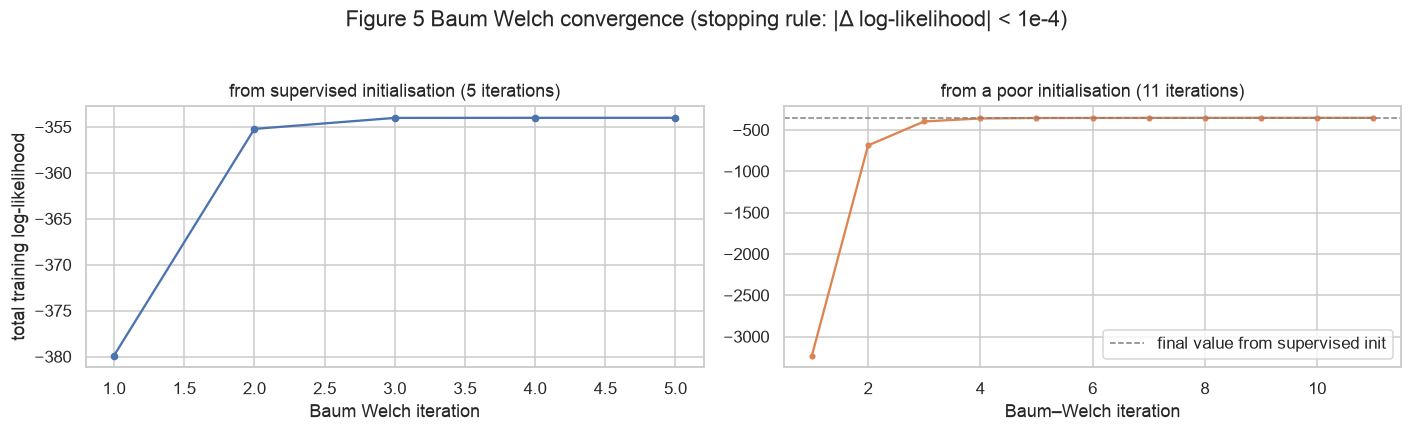

In [89]:
rng = np.random.default_rng(0)
hmm_poor = GaussianHMM(K, len(FEATURES), state_names=STATES, var_floor=VAR_FLOOR, trans_floor=1e-3)
hmm_poor.means = means_init + rng.normal(0, 0.75, size=means_init.shape)
hmm_poor.vars = np.ones_like(hmm_poor.vars)
print("Baum Welch from a poor initialisation:")
history_poor = hmm_poor.baum_welch(X_train_seqs, tol=1e-4, max_iter=500, verbose=False)
print(f"  {len(history_poor)} iterations, log-likelihood {history_poor[0]:.2f} → {history_poor[-1]:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(range(1, len(history) + 1), history, marker="o", ms=4)
axes[0].set_xlabel("Baum Welch iteration"); axes[0].set_ylabel("total training log-likelihood")
axes[0].set_title(f"from supervised initialisation ({len(history)} iterations)")
axes[1].plot(range(1, len(history_poor) + 1), history_poor, marker="o", ms=3, color="C1")
axes[1].axhline(history[-1], color="grey", ls="--", lw=1, label="final value from supervised init")
axes[1].set_xlabel("Baum–Welch iteration"); axes[1].set_title(f"from a poor initialisation ({len(history_poor)} iterations)")
axes[1].legend()
plt.suptitle("Figure 5 Baum Welch convergence (stopping rule: |Δ log-likelihood| < 1e-4)", y=1.03)
plt.tight_layout(); savefig("fig05_baum_welch_convergence.png"); plt.show()

### 7.3 Does the model still mean what we think it means?
Baum Welch is unsupervised, so we check that state *k* still corresponds to activity *k*
by decoding the training sequences.

In [90]:
train_pred = np.concatenate([hmm.viterbi(X)[0] for X in X_train_seqs])
train_true = np.concatenate(y_train_seqs)
print(f"training-set Viterbi accuracy: {(train_pred == train_true).mean():.4f}")
poor_pred = np.concatenate([hmm_poor.viterbi(X)[0] for X in X_train_seqs])
print(f"(model trained from the poor initialisation: {(poor_pred == train_true).mean():.4f} — "
      f"EM recovers the same state identities)")
print(pd.crosstab(pd.Series([STATES[i] for i in train_true], name="true"),
                  pd.Series([STATES[i] for i in train_pred], name="decoded")).reindex(index=STATES, columns=STATES))

training-set Viterbi accuracy: 0.9837
(model trained from the poor initialisation: 0.9837 — EM recovers the same state identities)
decoded   still  standing  walking  jumping
true                                       
still        56         1        0        0
standing      0        61        1        0
walking       0         0       67        2
jumping       0         0        0       58


### 7.4 Learned transition matrix A and initial distribution π

Saved figure to results/figure/fig06_transition_matrix.png


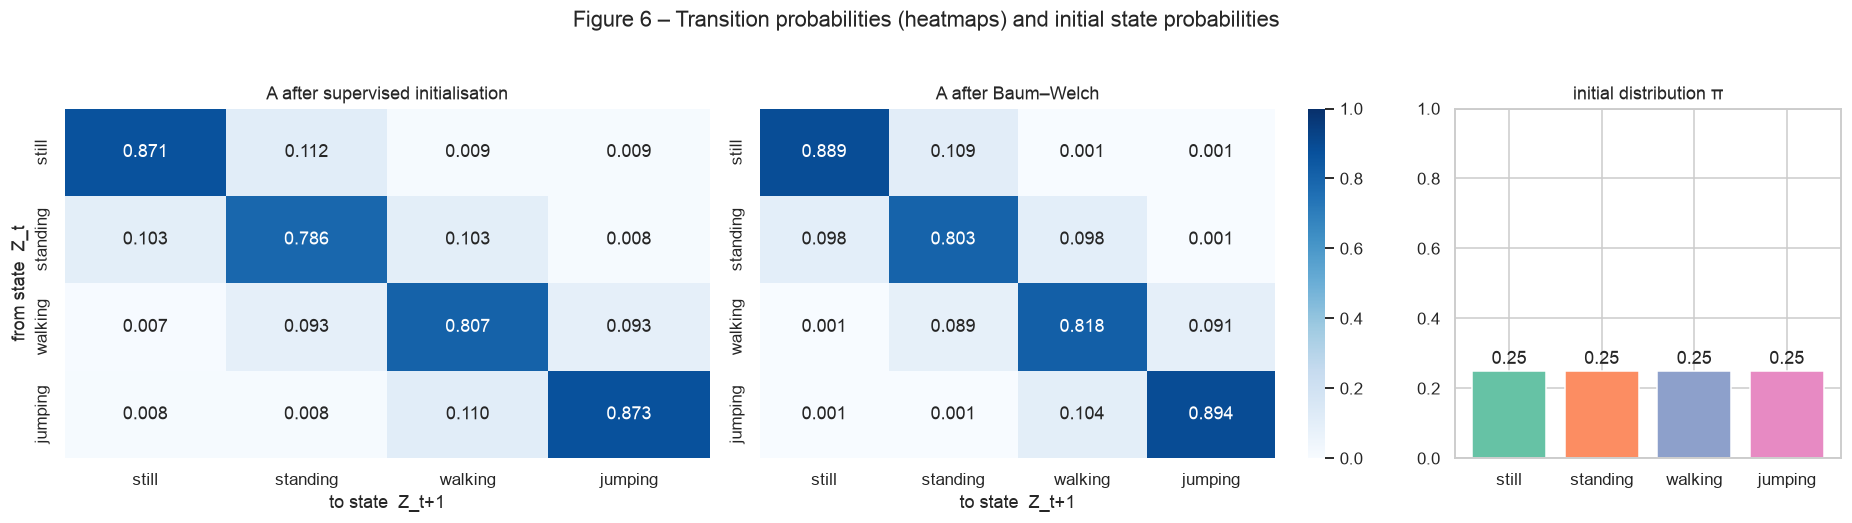

expected dwell time per state (windows ≈ seconds): {'still': np.float64(9.0), 'standing': np.float64(5.1), 'walking': np.float64(5.5), 'jumping': np.float64(9.5)}


In [91]:
A_learned = pd.DataFrame(hmm.A, index=STATES, columns=STATES)
A_learned.to_csv(os.path.join(RESULTS_DIR, "transition_matrix.csv"))
pd.DataFrame({"state": STATES, "pi_init": pi_init, "pi_learned": hmm.pi}).to_csv(os.path.join(RESULTS_DIR, "initial_probabilities.csv"), index=False)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1, 1, 0.6]})
sns.heatmap(pd.DataFrame(A_init, index=STATES, columns=STATES), annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=1, ax=axes[0], cbar=False)
axes[0].set_title("A after supervised initialisation"); axes[0].set_ylabel("from state  Z_t"); axes[0].set_xlabel("to state  Z_t+1")
sns.heatmap(A_learned, annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=1, ax=axes[1])
axes[1].set_title("A after Baum–Welch"); axes[1].set_ylabel(""); axes[1].set_xlabel("to state  Z_t+1")
axes[2].bar(STATES, hmm.pi, color=sns.color_palette("Set2", K))
axes[2].set_title("initial distribution π"); axes[2].set_ylim(0, 1)
for i, v in enumerate(hmm.pi):
    axes[2].text(i, v + 0.02, f"{v:.2f}", ha="center")
plt.suptitle("Figure 6 – Transition probabilities (heatmaps) and initial state probabilities", y=1.03)
plt.tight_layout(); savefig("fig06_transition_matrix.png"); plt.show()

expected_dwell = 1 / (1 - np.diag(hmm.A))
print("expected dwell time per state (windows ≈ seconds):", dict(zip(STATES, expected_dwell.round(1))))

### 7.5 Learned emission model B
With continuous observations the emission "matrix" is the set of per-state Gaussians. The
heatmap below shows the learned mean of every (normalised) feature in every state the
signature each activity leaves on the observation vector and the second panel shows the
learned standard deviations (how tightly each state constrains each feature).

Saved figure to results/figure/fig07_emission_model.png


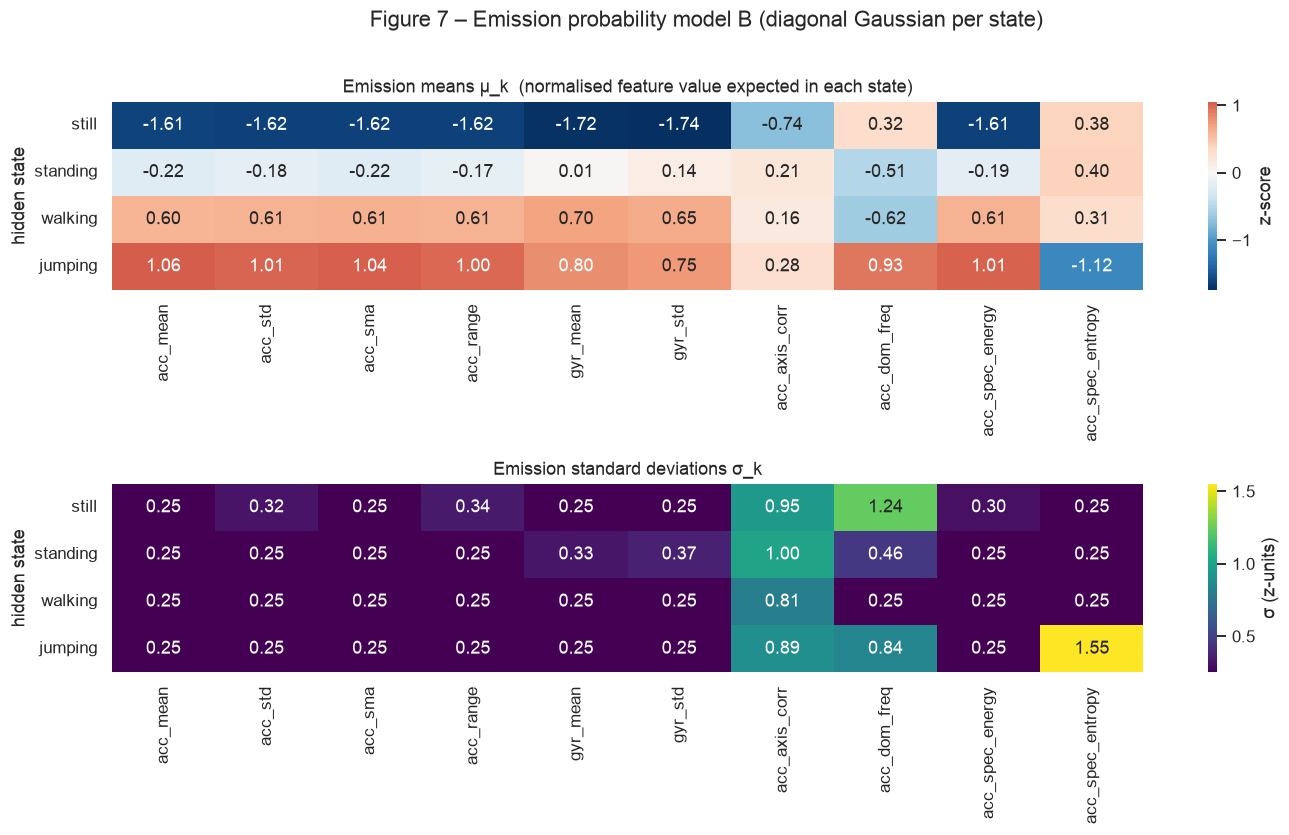

Saved figure to results/figure/fig08_emission_densities.png


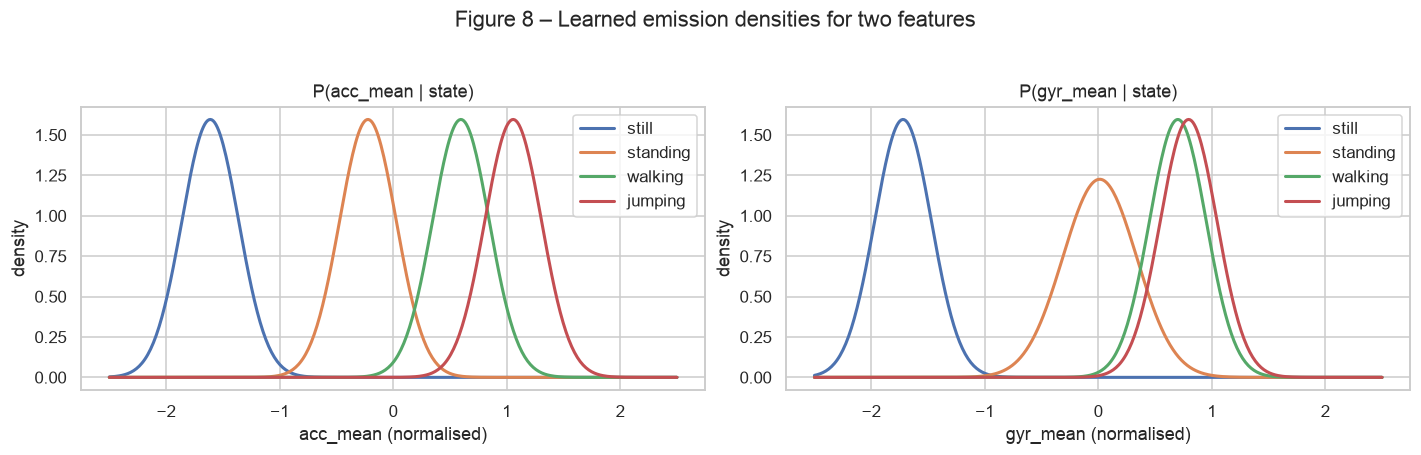

In [ ]:
em_means = pd.DataFrame(hmm.means, index=STATES, columns=FEATURES)
em_stds = pd.DataFrame(np.sqrt(hmm.vars), index=STATES, columns=FEATURES)
em_means.to_csv(os.path.join(RESULTS_DIR, "emission_means.csv")); em_stds.to_csv(os.path.join(RESULTS_DIR, "emission_stds.csv"))

fig, axes = plt.subplots(2, 1, figsize=(13, 7.5))
sns.heatmap(em_means, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[0], cbar_kws={"label": "z-score"})
axes[0].set_title("Emission means μ_k  (normalised feature value expected in each state)"); axes[0].set_xlabel("")
sns.heatmap(em_stds, annot=True, fmt=".2f", cmap="viridis", ax=axes[1], cbar_kws={"label": "σ (z-units)"})
axes[1].set_title("Emission standard deviations σ_k")
for ax in axes:
    ax.set_yticklabels(STATES, rotation=0); ax.set_ylabel("hidden state")
plt.suptitle("Figure 7 – Emission probability model B (diagonal Gaussian per state)", y=1.01)
plt.tight_layout(); savefig("fig07_emission_model.png"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, feat in zip(axes, ["acc_mean", "gyr_mean"]):
    j = FEATURES.index(feat)
    xs = np.linspace(-2.5, 2.5, 400)
    for k, s in enumerate(STATES):
        mu, sd = hmm.means[k, j], np.sqrt(hmm.vars[k, j])
        ax.plot(xs, np.exp(-0.5 * ((xs - mu) / sd) ** 2) / (sd * np.sqrt(2 * np.pi)), label=s, lw=2)
    ax.set_title(f"P({feat} | state)"); ax.set_xlabel(f"{feat} (normalised)"); ax.set_ylabel("density")
    ax.legend()
plt.suptitle("Figure 8 – Learned emission densities for two features", y=1.03)
plt.tight_layout(); savefig("fig08_emission_densities.png"); plt.show()

## 8. Evaluation on unseen data

**How the unseen data was obtained.** After the 52 training clips were recorded, eight *new,
longer* recordings (40–86 s, two per activity) were made in separate sessions later the same day,
in a different part of the room. None of them is used anywhere in training, feature scaling or
model selection. They were chained into two multi-activity **test sessions** so that the decoder
has real activity transitions to recover:

* `test_session_1.csv`: still → standing → walking → jumping (≈ 211 s, "wake up and get active")
* `test_session_2.csv`: jumping → walking → standing → still (≈ 177 s, "cool down and put the phone down")

Each session is pushed through exactly the same pre-processing, windowing, feature extraction
and (training-fitted) normalisation, then decoded with Viterbi.

In [94]:
test_sessions = {}
for name in ["test_session_1", "test_session_2"]:
    df = load_csv(os.path.join(DATA_DIR, "test", f"{name}.csv"))
    df, _ = resample_uniform(df)                 # segments were already edge-trimmed when the session was built
    feats = extract_clip(df)
    X = scaler.transform(feats)
    y = feats["activity"].map(STATE_IDX).values
    path, _ = hmm.viterbi(X)
    gamma = hmm.posterior(X)
    emission_only = hmm.log_emission(X).argmax(axis=1)   # baseline: per-window max-likelihood, no temporal model
    test_sessions[name] = dict(feats=feats, X=X, y=y, viterbi=path, posterior=gamma, emission_only=emission_only)
    print(f"{name}: {len(X)} windows | Viterbi accuracy = {(path == y).mean():.4f} | "
          f"emission-only accuracy = {(emission_only == y).mean():.4f}")

test_session_1: 209 windows | Viterbi accuracy = 0.9569 | emission-only accuracy = 0.9474
test_session_2: 176 windows | Viterbi accuracy = 0.9091 | emission-only accuracy = 0.9091


### 8.1 Decoded sequences

Saved figure to results/figure/fig09_decoded_test_session_1.png


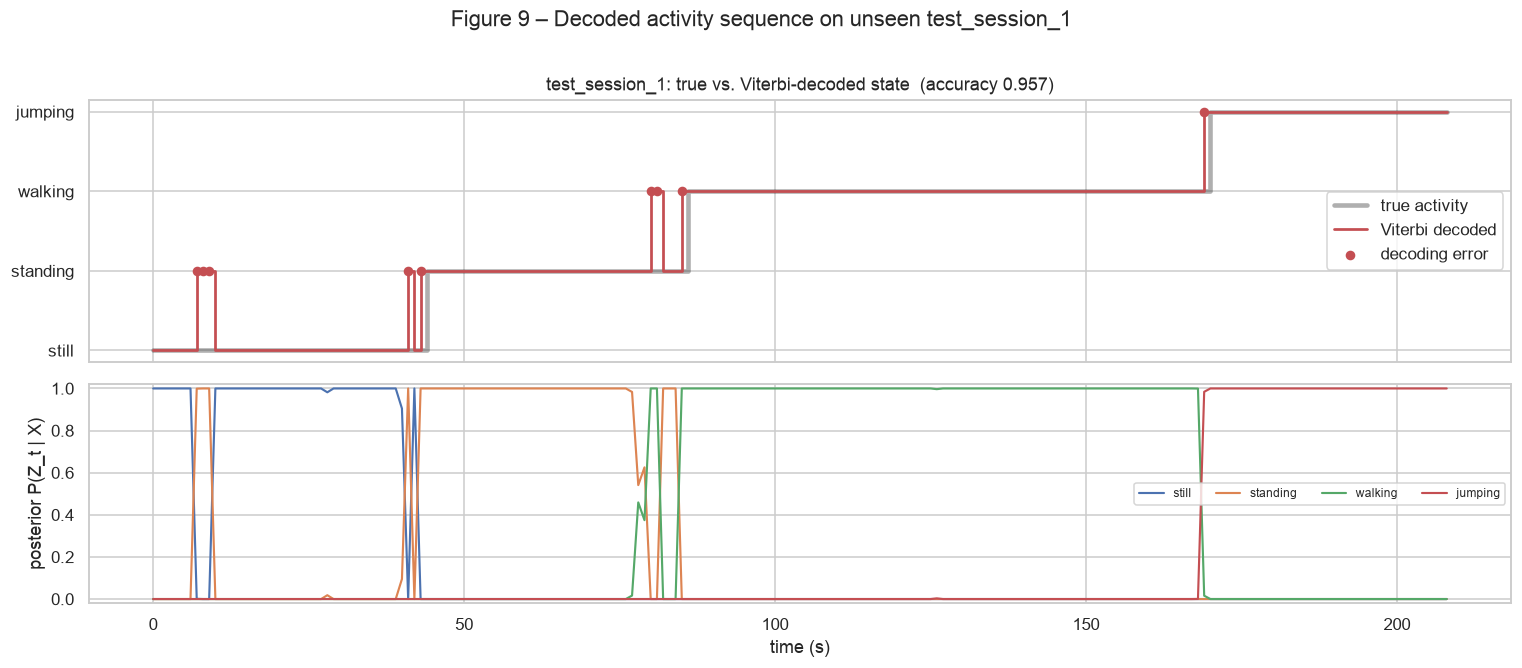

Saved figure to results/figure/fig10_decoded_test_session_2.png


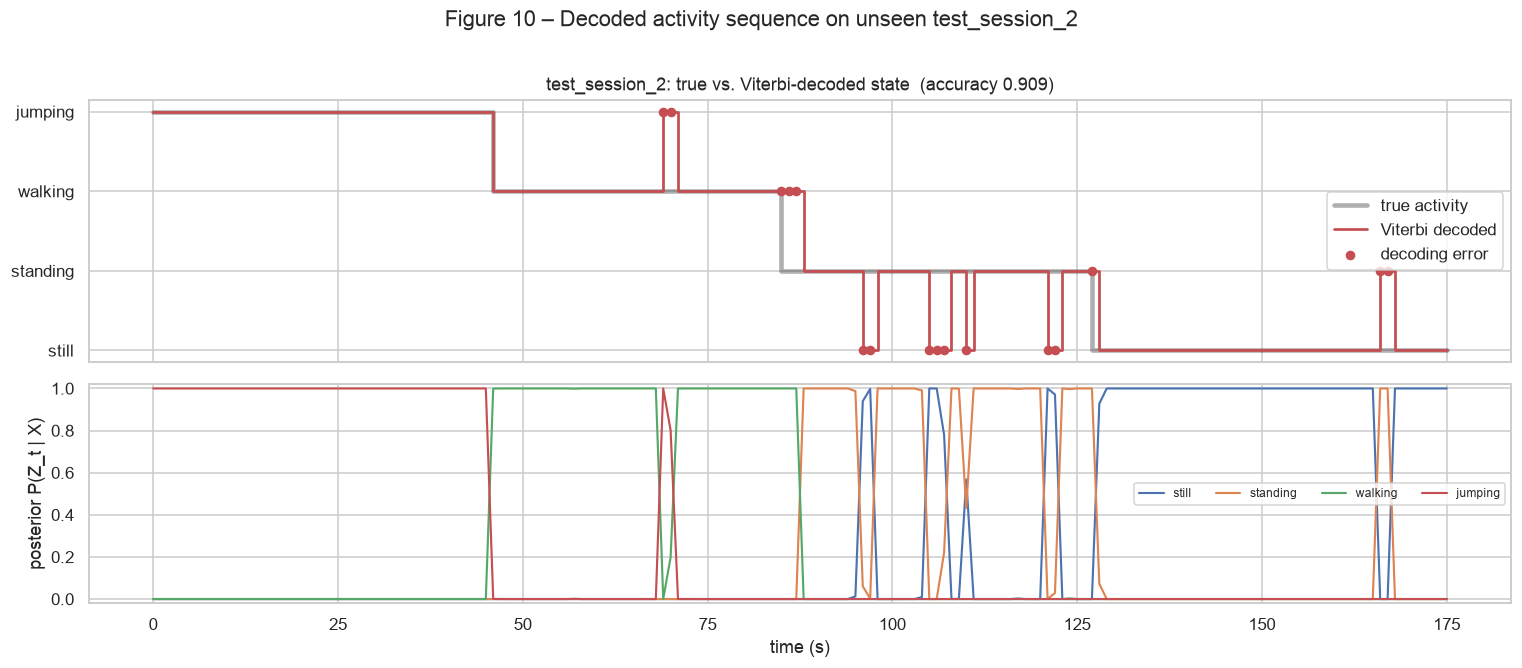

In [95]:
def plot_decoded(name, sess, fig_no):
    t = sess["feats"]["t_start"].values
    fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True, gridspec_kw={"height_ratios": [1.2, 1]})
    axes[0].step(t, sess["y"], where="post", lw=3, color="k", alpha=0.35, label="true activity")
    axes[0].step(t, sess["viterbi"], where="post", lw=1.8, color="C3", label="Viterbi decoded")
    wrong = sess["viterbi"] != sess["y"]
    axes[0].scatter(t[wrong], sess["viterbi"][wrong], color="C3", s=28, zorder=5, label="decoding error")
    axes[0].set_yticks(range(K)); axes[0].set_yticklabels(STATES)
    axes[0].set_title(f"{name}: true vs. Viterbi-decoded state  (accuracy {(sess['viterbi']==sess['y']).mean():.3f})")
    axes[0].legend(loc="center right")
    for k, s in enumerate(STATES):
        axes[1].plot(t, sess["posterior"][:, k], lw=1.4, label=s)
    axes[1].set_ylabel("posterior P(Z_t | X)"); axes[1].set_xlabel("time (s)"); axes[1].set_ylim(-0.02, 1.02)
    axes[1].legend(loc="center right", ncol=4, fontsize=8)
    plt.suptitle(f"Figure {fig_no} – Decoded activity sequence on unseen {name}", y=1.01)
    plt.tight_layout(); savefig(f"fig{fig_no:02d}_decoded_{name}.png"); plt.show()

plot_decoded("test_session_1", test_sessions["test_session_1"], 9)
plot_decoded("test_session_2", test_sessions["test_session_2"], 10)

### 8.2 Confusion matrix, sensitivity, specificity, accuracy

Evaluation on both unseen test sessions combined (Viterbi decoding):


,State (Activity),Number of Samples,Sensitivity,Specificity,Precision,Overall Accuracy
0,still,93,0.9140,0.9726,0.9140,0.9351
1,standing,84,0.8333,0.9734,0.8974,0.9351
2,walking,123,0.9756,0.9771,0.9524,0.9351
3,jumping,85,1.0000,0.9900,0.9659,0.9351



Per test file:


,test file,windows,Viterbi accuracy,emission-only accuracy
0,test_session_1,209,0.9569,0.9474
1,test_session_2,176,0.9091,0.9091
2,both combined,385,0.9351,0.9299


Saved figure to results/figure/fig11_confusion_matrix.png


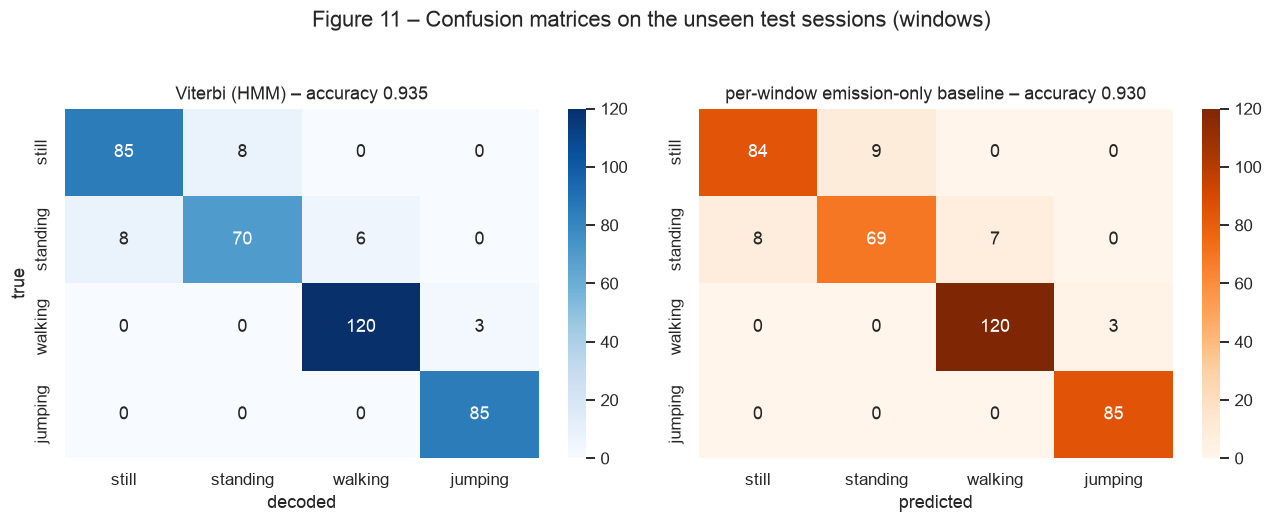

In [97]:
def confusion(y_true, y_pred, k=K):
    cm = np.zeros((k, k), dtype=int)
    for a, b in zip(y_true, y_pred):
        cm[a, b] += 1
    return cm

def metrics_table(cm):
    rows = []
    total = cm.sum(); correct = np.trace(cm)
    for k, s in enumerate(STATES):
        TP = cm[k, k]; FN = cm[k, :].sum() - TP; FP = cm[:, k].sum() - TP; TN = total - TP - FN - FP
        rows.append({"State (Activity)": s, "Number of Samples": int(cm[k, :].sum()),
                     "Sensitivity": TP / (TP + FN) if TP + FN else np.nan,
                     "Specificity": TN / (TN + FP) if TN + FP else np.nan,
                     "Precision": TP / (TP + FP) if TP + FP else np.nan,
                     "Overall Accuracy": correct / total})
    return pd.DataFrame(rows)

y_all = np.concatenate([s["y"] for s in test_sessions.values()])
v_all = np.concatenate([s["viterbi"] for s in test_sessions.values()])
e_all = np.concatenate([s["emission_only"] for s in test_sessions.values()])

cm = confusion(y_all, v_all)
table = metrics_table(cm)
print("Evaluation on both unseen test sessions combined (Viterbi decoding):")
display(table.round(4))
table.to_csv(os.path.join(RESULTS_DIR, "metrics_table.csv"), index=False)
pd.DataFrame(cm, index=[f"true {s}" for s in STATES], columns=[f"pred {s}" for s in STATES]).to_csv(os.path.join(RESULTS_DIR, "confusion_matrix.csv"))

per_session = pd.DataFrame([{"test file": n, "windows": len(s["y"]),
                             "Viterbi accuracy": (s["viterbi"] == s["y"]).mean(),
                             "emission-only accuracy": (s["emission_only"] == s["y"]).mean()}
                            for n, s in test_sessions.items()])
per_session.loc[len(per_session)] = ["both combined", len(y_all), (v_all == y_all).mean(), (e_all == y_all).mean()]
print("\nPer test file:")
display(per_session.round(4))
per_session.to_csv(os.path.join(RESULTS_DIR, "per_session_accuracy.csv"), index=False)

cm_e = confusion(y_all, e_all)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=STATES, yticklabels=STATES, ax=axes[0])
axes[0].set_title(f"Viterbi (HMM) – accuracy {(v_all==y_all).mean():.3f}"); axes[0].set_xlabel("decoded"); axes[0].set_ylabel("true")
sns.heatmap(cm_e, annot=True, fmt="d", cmap="Oranges", xticklabels=STATES, yticklabels=STATES, ax=axes[1])
axes[1].set_title(f"per-window emission-only baseline – accuracy {(e_all==y_all).mean():.3f}"); axes[1].set_xlabel("predicted"); axes[1].set_ylabel("")
plt.suptitle("Figure 11 – Confusion matrices on the unseen test sessions (windows)", y=1.03)
plt.tight_layout(); savefig("fig11_confusion_matrix.png"); plt.show()

### 8.3 Where do the errors happen?

25 mis-decoded windows out of 385


,session,t_start (s),true,decoded,posterior of true,boundary window
0,test_session_1,7.0,still,standing,0.001,False
1,test_session_1,8.0,still,standing,0.000,False
2,test_session_1,9.0,still,standing,0.000,False
3,test_session_1,41.0,still,standing,0.000,False
4,test_session_1,43.0,still,standing,0.000,True
5,test_session_1,80.0,standing,walking,0.000,False
6,test_session_1,81.0,standing,walking,0.000,False
7,test_session_1,85.0,standing,walking,0.000,True
8,test_session_1,169.0,walking,jumping,0.016,True
9,test_session_2,69.0,walking,jumping,0.000,False


Saved figure to results/figure/fig12_still_disturbances.png


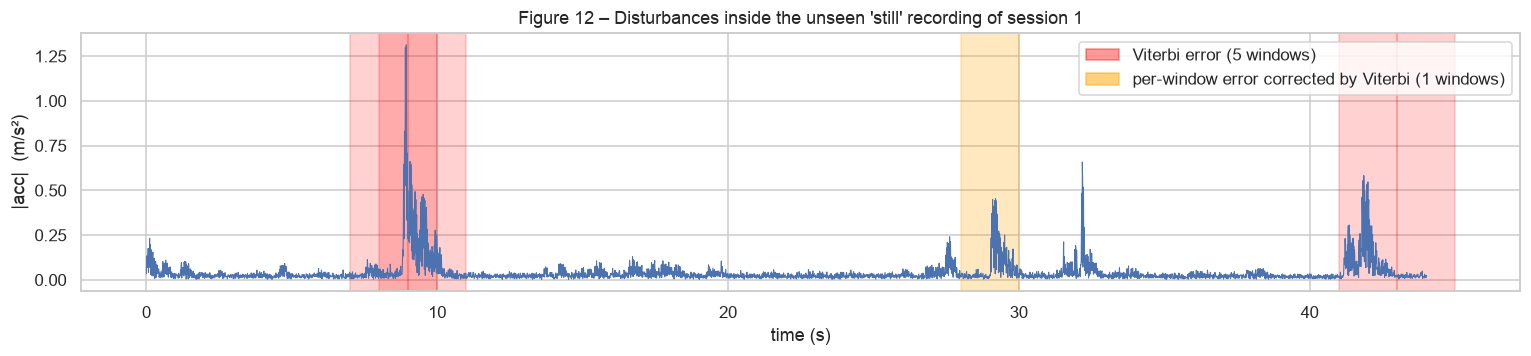

In [99]:
err_rows = []
for name, s in test_sessions.items():
    t = s["feats"]["t_start"].values
    for i in np.where(s["viterbi"] != s["y"])[0]:
        err_rows.append({"session": name, "t_start (s)": round(t[i], 1), "true": STATES[s["y"][i]],
                         "decoded": STATES[s["viterbi"][i]], "posterior of true": round(s["posterior"][i, s["y"][i]], 3),
                         "boundary window": bool(i > 0 and s["y"][i-1] != s["y"][i]) or bool(i < len(t)-1 and s["y"][i+1] != s["y"][i])})
errors = pd.DataFrame(err_rows)
print(f"{len(errors)} mis-decoded windows out of {len(y_all)}")
display(errors if len(errors) else "no errors")
if len(errors):
    errors.to_csv(os.path.join(RESULTS_DIR, "decoding_errors.csv"), index=False)

sess = test_sessions["test_session_1"]
seg = load_csv(os.path.join(DATA_DIR, "test", "test_session_1.csv"))
seg = seg[seg.source_file == "still_long_1.csv"]
a = np.linalg.norm(seg[["acc_x", "acc_y", "acc_z"]].values, axis=1)
t_win = sess["feats"]["t_start"].values
from matplotlib.patches import Patch
fig, ax = plt.subplots(figsize=(14, 3.4))
ax.plot(seg.time_s, a, lw=0.7)
n_fixed = n_err = 0
for i in range(len(t_win)):
    if sess["y"][i] == STATE_IDX["still"] and t_win[i] < seg.time_s.iloc[-1]:
        if sess["viterbi"][i] != sess["y"][i]:
            ax.axvspan(t_win[i], t_win[i] + WIN_S, color="red", alpha=0.18); n_err += 1
        elif sess["emission_only"][i] != sess["y"][i]:
            ax.axvspan(t_win[i], t_win[i] + WIN_S, color="orange", alpha=0.25); n_fixed += 1
ax.legend(handles=[Patch(color="red", alpha=0.4, label=f"Viterbi error ({n_err} windows)"),
                   Patch(color="orange", alpha=0.5, label=f"per-window error corrected by Viterbi ({n_fixed} windows)")], loc="upper right")
ax.set_xlabel("time (s)"); ax.set_ylabel("|acc|  (m/s²)")
ax.set_title("Figure 12 – Disturbances inside the unseen 'still' recording of session 1")
plt.tight_layout(); savefig("fig12_still_disturbances.png"); plt.show()

### 8.4 Robustness check: an activity order the model has never seen
The transition matrix encodes the "natural" order of activities. What happens on a session
with an unusual, direct transition (still → jumping, jumping → standing)? We chain the same
unseen long recordings in a different order to find out.

unusual-order session (still → jumping → standing → walking): Viterbi accuracy = 0.9118, 15 errors in 170 windows
Saved figure to results/figure/fig13_robustness_unusual_order.png


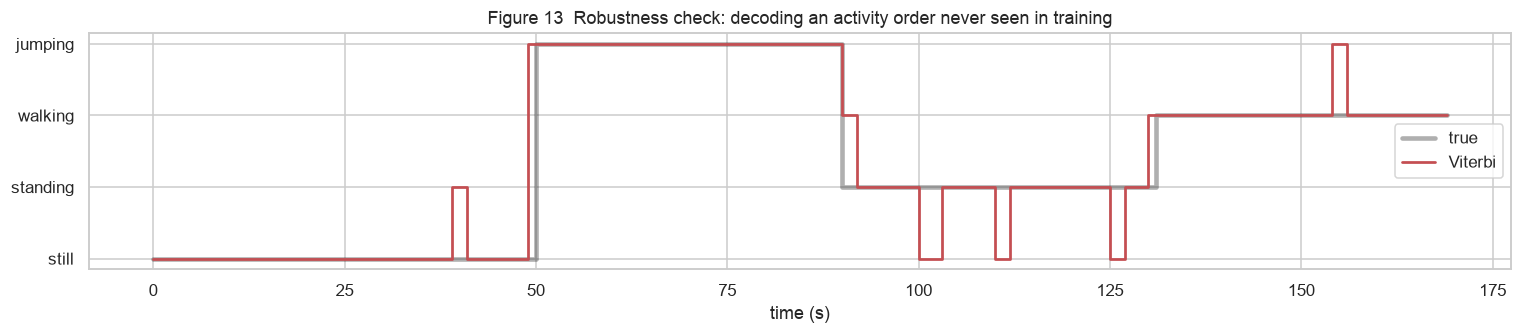

In [100]:
def chain_long(order):
    parts, t0 = [], 0.0
    for act, idx in order:
        d = trim_edges(load_csv(os.path.join(DATA_DIR, "test", f"{act}_long_{idx}.csv")))
        d["time_s"] += t0; t0 = d.time_s.iloc[-1] + 0.01
        parts.append(d)
    return pd.concat(parts, ignore_index=True)

stress = chain_long([("still", 2), ("jumping", 1), ("standing", 2), ("walking", 2)])
stress, _ = resample_uniform(stress)
feats_s = extract_clip(stress); X_s = scaler.transform(feats_s); y_s = feats_s["activity"].map(STATE_IDX).values
path_s, _ = hmm.viterbi(X_s)
print(f"unusual-order session (still → jumping → standing → walking): Viterbi accuracy = {(path_s == y_s).mean():.4f}, "
      f"{(path_s != y_s).sum()} errors in {len(y_s)} windows")
t = feats_s["t_start"].values
fig, ax = plt.subplots(figsize=(14, 3.2))
ax.step(t, y_s, where="post", lw=3, color="k", alpha=0.35, label="true"); ax.step(t, path_s, where="post", lw=1.8, color="C3", label="Viterbi")
ax.set_yticks(range(K)); ax.set_yticklabels(STATES); ax.set_xlabel("time (s)"); ax.legend(loc="center right")
ax.set_title("Figure 13  Robustness check: decoding an activity order never seen in training")
plt.tight_layout(); savefig("fig13_robustness_unusual_order.png"); plt.show()

### 8.5 Sensitivity analysis: how much does the temporal model help?
The variance floor (Section 6) controls how confident the emission model is allowed to be.
This cell retrains the HMM for several floor values and compares Viterbi decoding with the
per-window emission-only baseline on the unseen sessions. **The floor used above (σ = 0.25) was
fixed a priori; this sweep is a post-hoc analysis for the discussion, not model selection.**

,variance floor,sigma floor (z),EM iterations,Viterbi accuracy,emission-only accuracy,windows fixed by Viterbi,windows broken by Viterbi
0,0.0025,0.0500,8,0.9481,0.9455,1,0
1,0.0100,0.1000,9,0.9455,0.9455,0,0
2,0.0625,0.2500,5,0.9351,0.9299,2,0
3,0.1000,0.3162,7,0.9377,0.9351,2,1
4,0.2500,0.5000,5,0.9273,0.9221,4,2
5,0.5000,0.7071,6,0.9377,0.9065,14,2
6,1.0000,1.0000,19,0.9532,0.9065,19,1


Saved figure to results/figure/fig14_variance_floor_sensitivity.png


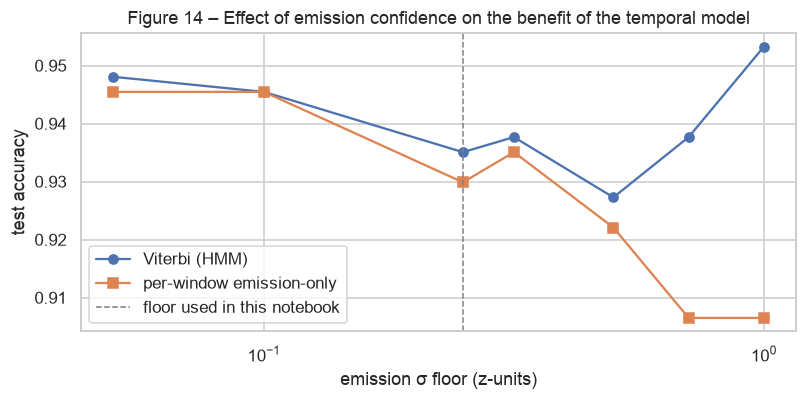

In [101]:
sweep_rows = []
for vf in [0.0025, 0.01, 0.0625, 0.1, 0.25, 0.5, 1.0]:
    m = GaussianHMM(K, len(FEATURES), state_names=STATES, var_floor=vf, trans_floor=1e-3)
    m.init_from_labels(X_train_seqs, y_train_seqs)
    h = m.baum_welch(X_train_seqs, tol=1e-4, max_iter=500, verbose=False)
    v = np.concatenate([m.viterbi(s["X"])[0] for s in test_sessions.values()])
    e = np.concatenate([m.log_emission(s["X"]).argmax(axis=1) for s in test_sessions.values()])
    sweep_rows.append({"variance floor": vf, "sigma floor (z)": np.sqrt(vf), "EM iterations": len(h),
                       "Viterbi accuracy": (v == y_all).mean(), "emission-only accuracy": (e == y_all).mean(),
                       "windows fixed by Viterbi": int(((e != y_all) & (v == y_all)).sum()),
                       "windows broken by Viterbi": int(((e == y_all) & (v != y_all)).sum())})
sweep = pd.DataFrame(sweep_rows)
display(sweep.round(4))
sweep.to_csv(os.path.join(RESULTS_DIR, "variance_floor_sensitivity.csv"), index=False)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(sweep["sigma floor (z)"], sweep["Viterbi accuracy"], marker="o", label="Viterbi (HMM)")
ax.plot(sweep["sigma floor (z)"], sweep["emission-only accuracy"], marker="s", label="per-window emission-only")
ax.axvline(np.sqrt(VAR_FLOOR), color="grey", ls="--", lw=1, label="floor used in this notebook")
ax.set_xscale("log"); ax.set_xlabel("emission σ floor (z-units)"); ax.set_ylabel("test accuracy"); ax.legend()
ax.set_title("Figure 14 – Effect of emission confidence on the benefit of the temporal model")
plt.tight_layout(); savefig("fig14_variance_floor_sensitivity.png"); plt.show()